In [11]:
import pandas as pd
import matplotlib.pyplot as plt

look_ahead = pd.read_parquet('look_ahead_results.parquet')
lp = pd.read_parquet('lp_results.parquet')

print('Look Ahead:', look_ahead.shape)
print('LP:', lp.shape)

Look Ahead: (287, 6)
LP: (288, 6)


In [12]:
display(look_ahead.head())
display(lp.head())

,Interval,Current Price,Next Price,Action,Battery,Profit
0,1,26.92,23.70,SELL,Empty,26.92
1,2,23.70,23.86,BUY,FULL,3.22
2,3,23.86,23.62,SELL,Empty,27.08
3,4,23.62,23.50,HOLD,Empty,27.08
4,5,23.50,22.21,HOLD,Empty,27.08


,interval,Current Price,Next Price,Action,Battery,Profit
0,1,26.92,23.70,Sell,Empty,26.92
1,2,23.70,23.86,Buy,Full,3.22
2,3,23.86,23.62,Sell,Empty,27.08
3,4,23.62,23.50,Hold,Empty,27.08
4,5,23.50,22.21,Hold,Empty,27.08


In [13]:
#cash flow
look_ahead_profit = look_ahead["Profit"].iloc[-1]
lp_profit = lp["Profit"].iloc[-1]

print("Look Ahead Cash Flow: $", round(look_ahead_profit, 2))
print("LP Cash Flow: $", round(lp_profit, 2))

Look Ahead Cash Flow: $ 277.1
LP Cash Flow: $ 302.87


In [15]:
look_ahead_buys = (look_ahead["Action"] == "BUY").sum()
look_ahead_sells = (look_ahead["Action"] == "SELL").sum()

lp_buys = (lp["Action"] == "Buy").sum()
lp_sells = (lp["Action"] == "Sell").sum()

comparison = pd.DataFrame({
    "Algorithm": ["Look Ahead", "LP"],
    "Cash Flow": [look_ahead_profit, lp_profit],
    "Buys": [look_ahead_buys, lp_buys],
    "Sells": [look_ahead_sells, lp_sells]
})

display(comparison)

,Algorithm,Cash Flow,Buys,Sells
0,Look Ahead,277.10,47,47
1,LP,302.87,47,48


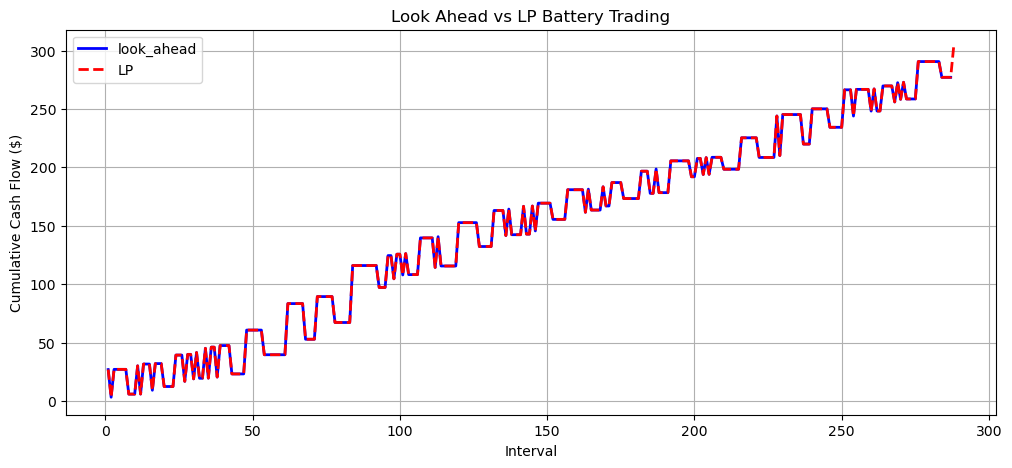

In [21]:
#plotting results
plt.figure(figsize=(12, 5))

plt.plot(
    look_ahead["Interval"],
    look_ahead["Profit"],
    label="look_ahead",
     color="blue",
    linewidth=2
)

plt.plot(
    lp["interval"],
    lp["Profit"],
    label="LP",
    color = 'red',
    linestyle="--",
    linewidth=2
)

plt.xlabel("Interval")
plt.ylabel("Cumulative Cash Flow ($)")
plt.title("Look Ahead vs LP Battery Trading")
plt.legend()
plt.grid(True)

plt.show()